# 09 · From infrared light to temperature

**Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.**

A school in Kingston wants to know whether its roof heats up more than the trees beside it. A weather team looking offshore from Portland wants to know whether a cold cloud will bring rain. Both teams see an infrared signal. Work out what that signal can support. The temperatures, material properties and cloud pixels in this lab are synthetic.

## Two ways a satellite sees Earth

A visible sensor receives sunlight reflected by the scene. A thermal infrared sensor receives radiance that includes energy emitted by the surface, clouds and atmosphere. NOAA lists a visible red channel and a longwave infrared window channel for the GOES Advanced Baseline Imager. The longwave channel can record emitted energy after dark. The scene still needs enough context to tell you what is emitting. [NOAA ABI channel summary](https://www.nesdis.noaa.gov/our-satellites/currently-flying/goes-east-west/abi-scan-mode-information-and-channel-summary)

Radiance describes the energy arriving from a direction. Spectral radiance also specifies the wavelength interval. For an ideal emitter, Planck's law relates the spectral radiance to absolute temperature:

$$
B_\lambda(T)=\frac{2hc^2}{\lambda^5}\frac{1}{\exp(hc/(\lambda k_B T))-1}.
$$

Use metres for $\lambda$ and kelvin for $T$. The formula returns radiance per metre of wavelength. Multiply by $10^{-6}$ to express it per micrometre. The inverse gives **brightness temperature**, the temperature an ideal emitter would need to produce the given radiance at that wavelength. [NIST, radiance-temperature calibration](https://nvlpubs.nist.gov/nistpubs/Legacy/SP/nistspecialpublication250-43.pdf) · [NIST, physical constants](https://physics.nist.gov/cuu/Constants/)

The code uses a single illustrative wavelength of 10.9 μm. Real instruments respond to a range of wavelengths. The USGS Landsat Level-1 workflow uses the thermal constants in each scene's metadata to convert calibrated radiance to top-of-atmosphere brightness temperature. [USGS, Landsat Level-1 conversions](https://www.usgs.gov/landsat-missions/using-usgs-landsat-level-1-data-product)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Exact SI defining constants. See the NIST reference above.
PLANCK_J_S = 6.62607015e-34
LIGHT_M_S = 299792458
BOLTZMANN_J_K = 1.380649e-23
WAVELENGTH_M = 10.9e-6
RADIANCE_FACTOR = 2 * PLANCK_J_S * LIGHT_M_S**2 / WAVELENGTH_M**5 * 1e-6
TEMPERATURE_FACTOR_K = PLANCK_J_S * LIGHT_M_S / (WAVELENGTH_M * BOLTZMANN_J_K)


def thermal_radiance(temperature_k):
    # Return blackbody radiance per micrometre at the teaching wavelength.
    temperature_k = np.asarray(temperature_k, dtype=float)
    if np.any(~np.isfinite(temperature_k) | (temperature_k <= 0)):
        raise ValueError("Temperature must be finite and positive in kelvin.")
    return RADIANCE_FACTOR / np.expm1(TEMPERATURE_FACTOR_K / temperature_k)


def brightness_temperature(radiance_per_um):
    # Invert the same single-wavelength model.
    radiance_per_um = np.asarray(radiance_per_um, dtype=float)
    if np.any(~np.isfinite(radiance_per_um) | (radiance_per_um <= 0)):
        raise ValueError("Radiance must be finite and positive.")
    return TEMPERATURE_FACTOR_K / np.log1p(RADIANCE_FACTOR / radiance_per_um)


np.testing.assert_allclose(
    brightness_temperature(thermal_radiance([230, 300, 325])), [230, 300, 325]
)

## Scenario 1 · A Kingston school roof and its shade trees

Start with a roof at 320 K and a canopy at 300 K. The model assumes a transparent atmosphere and ignores reflected environmental infrared radiation. Emissivity $\epsilon$ scales emission relative to an ideal emitter, so $L=\epsilon B_\lambda(T)$. The two emissivities below are teaching inputs. A field team would need material information or a suitable surface-temperature product before assigning them to real pixels.

Compare each true temperature with the brightness temperature inferred from its emitted radiance. Next, place both materials in a single pixel. The pixel combines their radiances, weighted by the area each covers in this simplified view. Invert the combined radiance once. A simple average of the two temperatures takes a different path through the nonlinear equation.

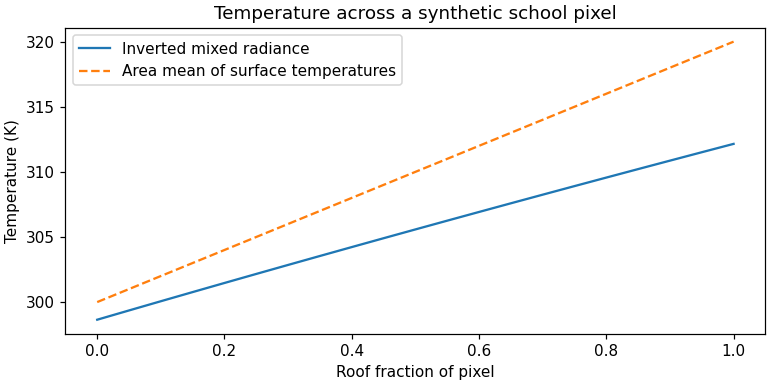

Roof    Surface 320.0 K  Brightness 312.15 K
Canopy  Surface 300.0 K  Brightness 298.65 K
Half roof: brightness 305.58 K, area mean 310.00 K


In [2]:
roof_k, canopy_k = 320.0, 300.0
roof_emissivity, canopy_emissivity = 0.90, 0.98
roof_radiance = roof_emissivity * thermal_radiance(roof_k)
canopy_radiance = canopy_emissivity * thermal_radiance(canopy_k)

for label, surface, radiance in (
    ("Roof", roof_k, roof_radiance), ("Canopy", canopy_k, canopy_radiance)
):
    print(f"{label:6}  Surface {surface:.1f} K  Brightness {brightness_temperature(radiance):.2f} K")

roof_fraction = np.linspace(0, 1, 21)
mixed_radiance = roof_fraction * roof_radiance + (1 - roof_fraction) * canopy_radiance
mixed_brightness_k = brightness_temperature(mixed_radiance)
area_mean_k = roof_fraction * roof_k + (1 - roof_fraction) * canopy_k
print(f"Half roof: brightness {mixed_brightness_k[10]:.2f} K, area mean {area_mean_k[10]:.2f} K")

fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.plot(roof_fraction, mixed_brightness_k, label="Inverted mixed radiance")
ax.plot(roof_fraction, area_mean_k, "--", label="Area mean of surface temperatures")
ax.set(xlabel="Roof fraction of pixel", ylabel="Temperature (K)",
       title="Temperature across a synthetic school pixel")
ax.legend()
plt.show()

**Try it.** Set the two surfaces to the same physical temperature while keeping their emissivities different. Explain the apparent temperature difference. Then set both emissivities to 1 and recompute the half-roof pixel using the original temperatures. Compare the result with the 310 K area mean. The second run isolates Planck nonlinearity from emissivity.

For an observed Kingston comparison, use a quality-screened Landsat Collection 2 surface-temperature product and document cloud masks and acquisition time. USGS uses emissivity inputs and atmospheric profiles in the retrieval. To answer a question about students' exposure to hot air, add measurements at the height and time relevant to the students. [USGS, Landsat surface temperature](https://www.usgs.gov/landsat-missions/landsat-collection-2-surface-temperature) · [USGS, retrieval inputs](https://www.usgs.gov/landsat-missions/landsat-collection-2-atmospheric-auxiliary-data)

## Scenario 2 · A cold cloud offshore from Portland

Two invented pixels have the same 235 K infrared brightness temperature. One has rain below it in the scenario and the other has none. Run the calculation to see what happens when you apply the same cold-pixel rule to both.

The setup isolates a measurement problem. A longwave window channel responds to the radiating scene. A rain-rate estimate requires additional information about precipitation. IMERG combines several inputs, including passive microwave estimates and infrared-based estimates, as described in NASA's algorithm documentation. [NOAA ABI channel summary](https://www.nesdis.noaa.gov/our-satellites/currently-flying/goes-east-west/abi-scan-mode-information-and-channel-summary) · [NASA IMERG V07](https://gpm.nasa.gov/resources/documents/imerg-v07-technical-documentation)

In [3]:
cloud_temperature_k = np.array([235.0, 235.0])
teaching_rain_rate_mm_h = np.array([0.0, 18.0])
cold_pixel_flag = cloud_temperature_k < 245
for i, (temp, flag, rain) in enumerate(
    zip(cloud_temperature_k, cold_pixel_flag, teaching_rain_rate_mm_h), start=1
):
    print(f"Pixel {i}: {temp:.0f} K, cold flag {flag}, synthetic rain rate {rain:.0f} mm/h")

assert cold_pixel_flag.all()
assert teaching_rain_rate_mm_h[0] != teaching_rain_rate_mm_h[1]

Pixel 1: 235 K, cold flag True, synthetic rain rate 0 mm/h
Pixel 2: 235 K, cold flag True, synthetic rain rate 18 mm/h


## Submit your interpretation

Report the half-roof result with units and explain what changed when you adjusted emissivity. Write a two-sentence recommendation for the Portland team. Name a time-matched rainfall estimate or observation that would let you test the rule, and explain how a point gauge and a satellite footprint might sample different parts of a shower.